In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import BalancedRandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
	accuracy_score,
	precision_score,
	recall_score,
	f1_score,
	roc_auc_score,
	classification_report,
	precision_recall_curve,
	auc,
	confusion_matrix,
	roc_curve,
	average_precision_score,
	precision_recall_fscore_support,
)

In [ ]:
print("XGBoost version:", xgb.__version__)
build_info = xgb.build_info() if hasattr(xgb, "build_info") else {}
print("XGBoost CUDA build support:", build_info.get("USE_CUDA", "unknown (older XGBoost version)"))

In [2]:
import sys
print(sys.executable)

e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Scripts\python.exe


In [3]:
df = pd.read_csv("dataset/creditcard.csv")

In [4]:
df.sample(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
60623,49412.0,1.230015,-0.015170,0.642428,1.002520,-0.046740,0.986164,-0.631116,0.295957,0.771444,...,-0.092586,-0.068243,-0.132107,-1.325264,0.497409,-0.281128,0.082120,0.020002,1.00,0
120655,75909.0,-0.368603,0.696059,-0.119370,0.206842,2.603286,3.827858,0.066760,0.885776,-0.453033,...,-0.054711,-0.109386,-0.145521,1.016341,0.032641,-0.273776,0.053182,0.139285,4.73,0
262255,160385.0,-0.637047,-0.455979,0.084606,-4.188968,1.996900,3.671970,-0.286114,0.713576,-2.139089,...,-0.262140,-0.242663,-0.402168,0.678611,0.771122,-0.123668,-0.014856,-0.122358,20.00,0
247504,153597.0,-0.633123,-0.175686,1.663739,-2.391704,-0.595771,0.993120,-0.816102,0.620610,0.401678,...,0.124063,0.625368,-0.224260,0.083275,-0.184300,-0.294576,0.519735,0.266567,2.00,0
262433,160473.0,-0.219146,1.201012,-0.782866,-0.474595,0.465915,-0.911031,0.623805,0.348553,-0.117871,...,-0.295598,-0.896008,0.201724,0.607409,-0.420358,0.113707,0.086993,0.022167,19.26,0


In [5]:
df.shape

(284807, 31)

In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [8]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [9]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
class_counts = df['Class'].value_counts()
print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


In [11]:
fraud_percentage = (class_counts[1] / len(df)) * 100
print(f"Fraud percentage: {fraud_percentage:.4f}%")

Fraud percentage: 0.1727%


# Fraud vs Non-Fraud Amount Distribution

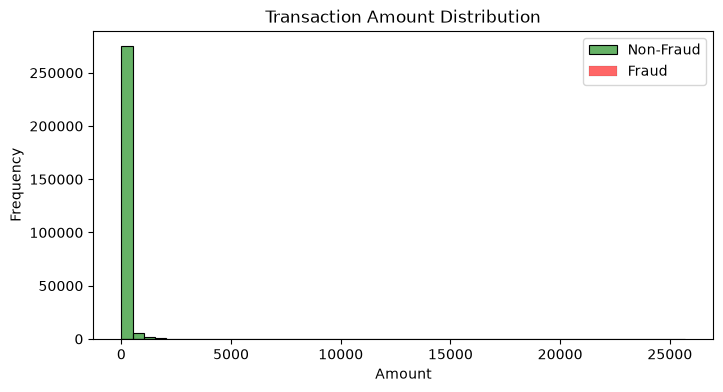

In [12]:
plt.figure(figsize=(8,4))
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='green', label='Non-Fraud', alpha=0.6)
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='red', label='Fraud', alpha=0.6)
plt.legend()
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()

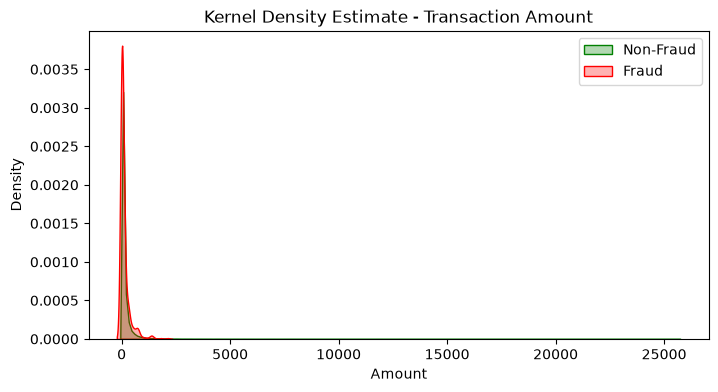

In [13]:
plt.figure(figsize=(8,4))
sns.kdeplot(df[df['Class']==0]['Amount'], color='green', label='Non-Fraud', fill=True, alpha=0.3)
sns.kdeplot(df[df['Class']==1]['Amount'], color='red', label='Fraud', fill=True, alpha=0.3)
plt.title('Kernel Density Estimate - Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Density')
plt.legend()
plt.show()

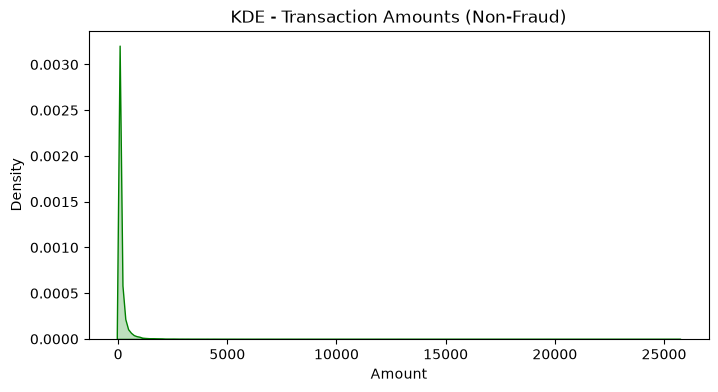

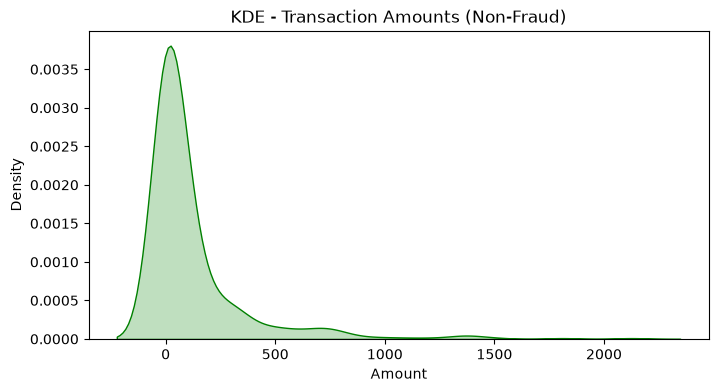

In [14]:
plt.figure(figsize=(8,4))
sns.kdeplot(df[df['Class']==0]['Amount'], color='green', fill=True)
plt.title('KDE - Transaction Amounts (Non-Fraud)')
plt.xlabel('Amount')
plt.ylabel('Density')
plt.show()

plt.figure(figsize=(8,4))
sns.kdeplot(df[df['Class']==1]['Amount'], color='green', fill=True)
plt.title('KDE - Transaction Amounts (Non-Fraud)')
plt.xlabel('Amount')
plt.ylabel('Density')
plt.show()

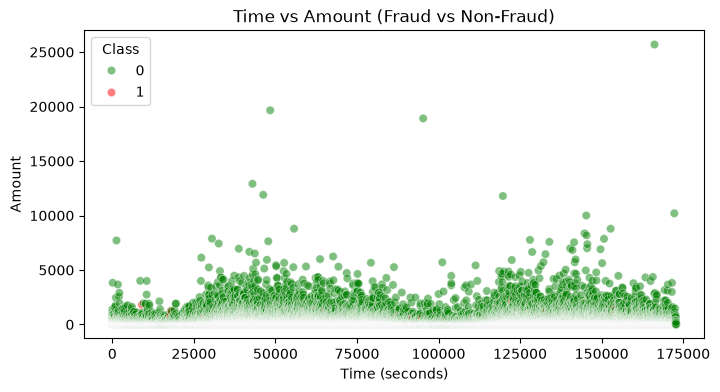

In [18]:
plt.figure(figsize=(8,4))
sns.scatterplot(x='Time', y='Amount', hue='Class', data=df, palette=['green','red'], alpha=0.5)
plt.title('Time vs Amount (Fraud vs Non-Fraud)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amount')
plt.show()


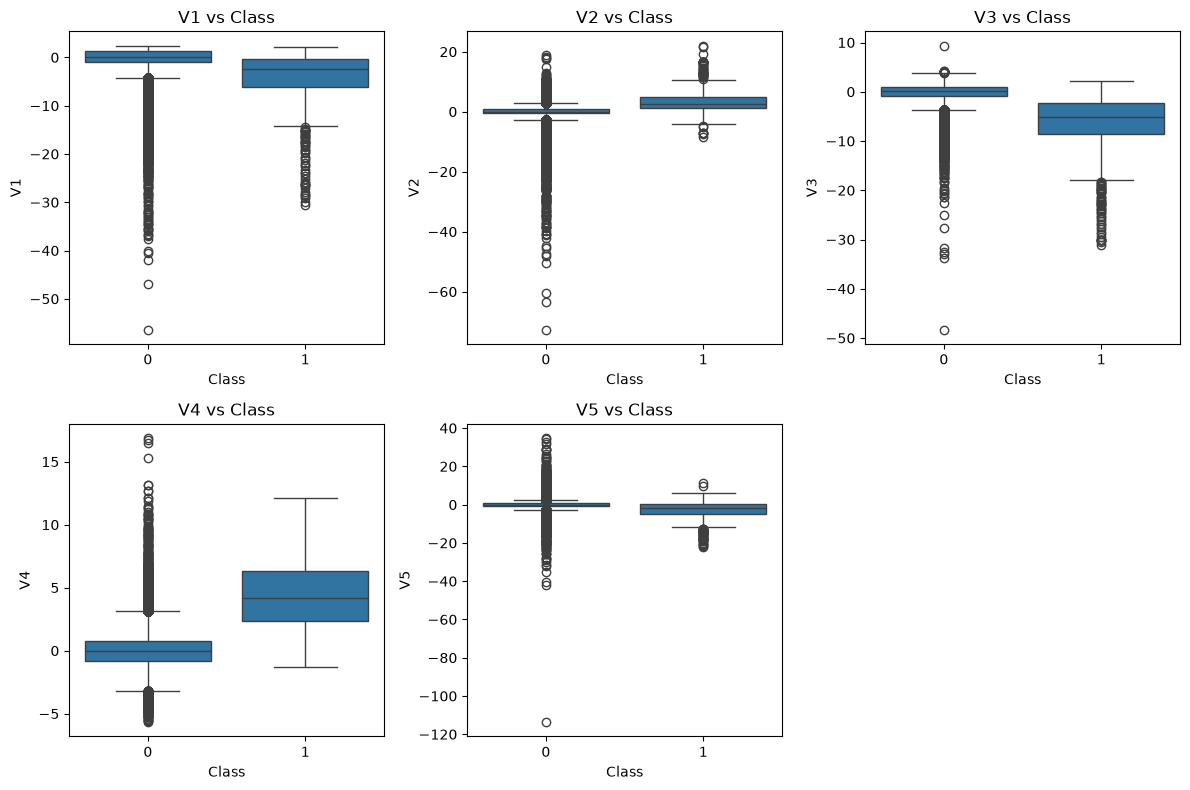

In [15]:
features = ['V1', 'V2', 'V3', 'V4', 'V5']
plt.figure(figsize=(12,8))
for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='Class', y=feature, data=df)
    plt.title(f'{feature} vs Class')
plt.tight_layout()
plt.show()


In [16]:
scaler = RobustScaler()
df[['Amount','Time']] = scaler.fit_transform(df[['Amount','Time']])

In [17]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-0.994983,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,1.783274,0
1,-0.994983,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.269825,0
2,-0.994972,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,0
3,-0.994972,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,0
4,-0.994960,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.670579,0


# Random Under-Sampling

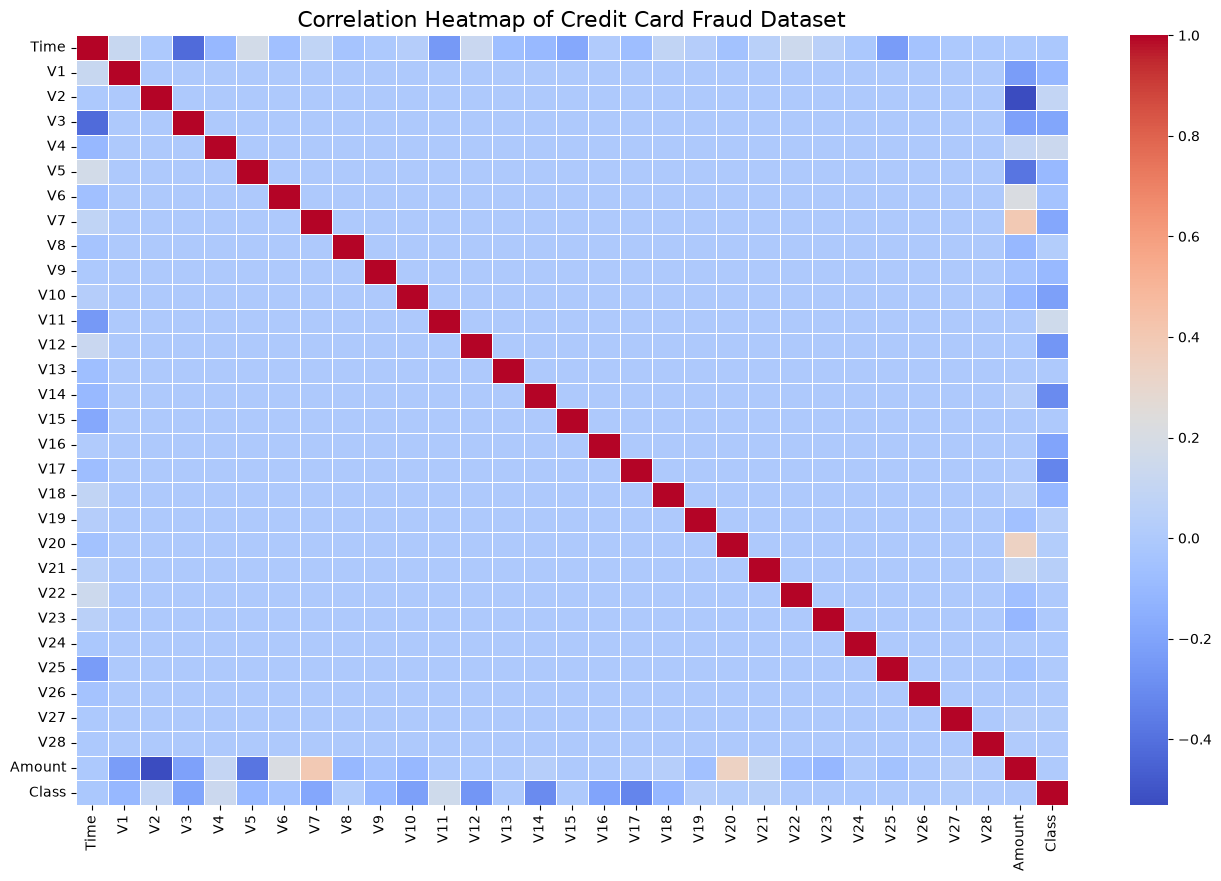

In [18]:
corr_matrix = df.corr()

# Plot heatmap
plt.figure(figsize=(16, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title('Correlation Heatmap of Credit Card Fraud Dataset', fontsize=16)
plt.show()

Correlation of features with Class:
V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64


C:\Users\Utkarsh\AppData\Local\Temp\ipykernel_42572\2177458204.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlation_with_class.values, y=correlation_with_class.index, palette="viridis")


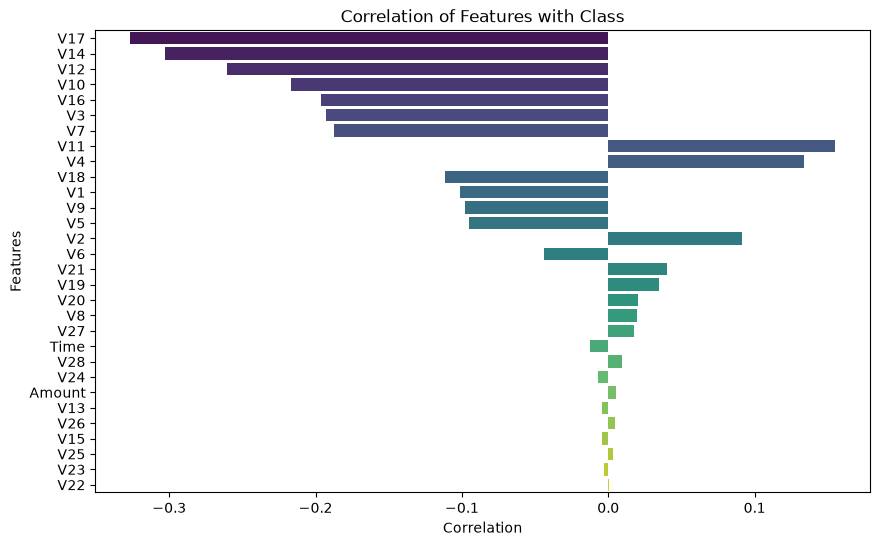

In [19]:
# Correlation of all features with Class
correlation_with_class = df.corr()['Class'].drop('Class').sort_values(key=abs, ascending=False)

print("Correlation of features with Class:")
print(correlation_with_class)

plt.figure(figsize=(10,6))
sns.barplot(x=correlation_with_class.values, y=correlation_with_class.index, palette="viridis")
plt.title("Correlation of Features with Class")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.show()

In [20]:
subSample_fraud = df[df['Class']==1]
fraud_count = len(subSample_fraud)

subSample_nonfraud = df[df['Class']==0].sample(n=fraud_count, random_state = 42)

subSample = pd.concat([subSample_fraud,subSample_nonfraud],axis=0)
subSample = subSample.sample(frac=1).reset_index(drop=True)

In [21]:
subSample.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-0.436413,1.176716,0.557091,-0.490800,0.756424,0.249192,-0.781871,0.228750,-0.040840,-0.432111,...,-0.062166,-0.128168,-0.040176,0.110040,0.437891,0.368809,-0.018287,0.031173,-0.296793,1
1,-0.039004,-0.885254,1.790649,-0.945149,3.853433,-1.543510,0.188582,-2.988383,1.344059,-2.294535,...,0.746160,0.550802,-0.034882,-0.567608,-0.528318,0.258782,0.506893,0.176736,-0.201635,1
2,0.556797,-0.361428,1.133472,-2.971360,-0.283073,0.371452,-0.574680,4.031513,-0.934398,-0.768255,...,0.110815,0.563861,-0.408436,-0.880079,1.408392,-0.137402,-0.001250,-0.182751,6.409837,1
3,0.029570,1.995015,-0.136854,-0.700744,1.339728,0.141749,0.322486,-0.228162,0.023713,1.164500,...,-0.579671,-1.333333,0.306777,-1.132687,-0.176192,-1.039223,0.059782,-0.039761,-0.167819,0
4,0.516583,1.851039,-0.995222,-1.804547,-0.845797,1.590379,3.873163,-1.197684,1.026194,1.354591,...,0.217816,0.615750,0.116846,0.748963,-0.157073,0.138871,0.022868,-0.036785,0.739887,0


In [22]:
(subSample['Class']).value_counts()

Class
1    492
0    492
Name: count, dtype: int64

<Axes: xlabel='Class', ylabel='count'>

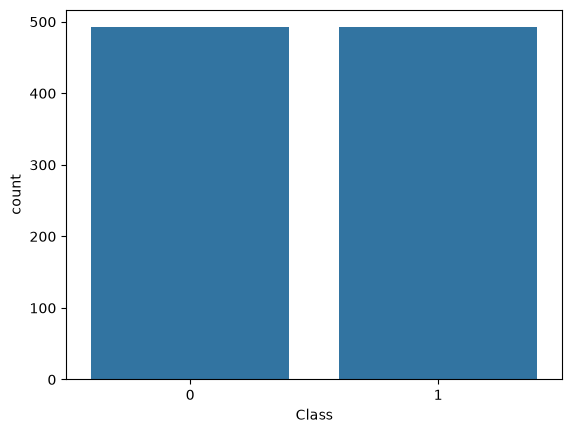

In [27]:
sns.countplot(data=subSample,x='Class')

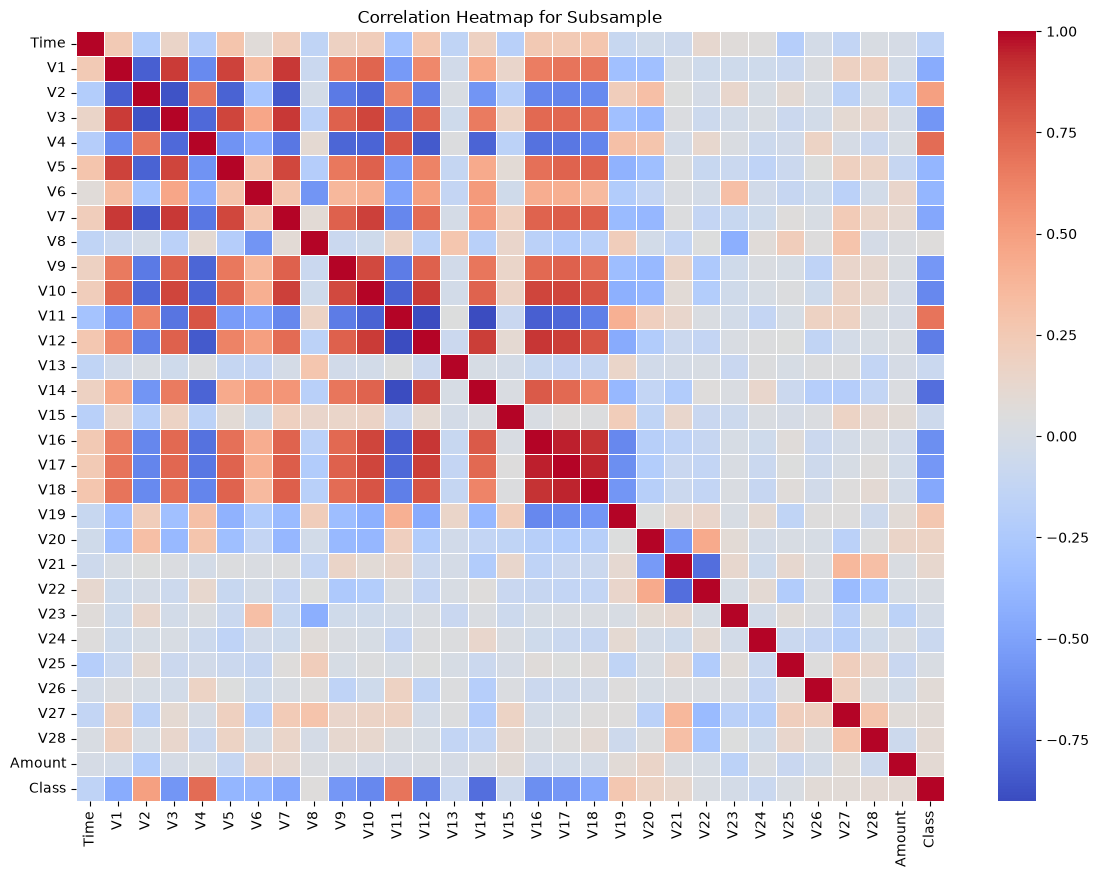

In [23]:
corr_matrix = subSample.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title('Correlation Heatmap for Subsample')
plt.show()

C:\Users\Utkarsh\AppData\Local\Temp\ipykernel_42572\1186846003.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_corr.values, y=sorted_corr.index, palette="viridis")


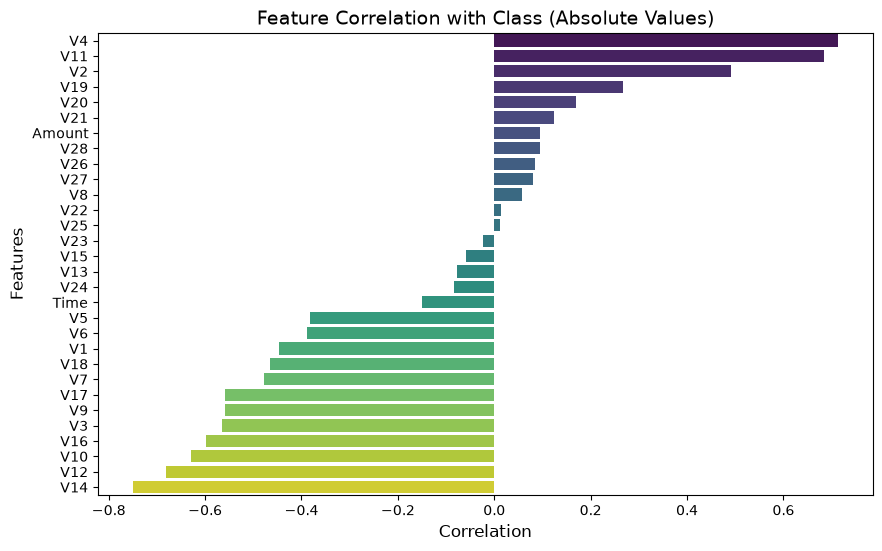

In [24]:
class_corr = subSample.corr()['Class'].drop('Class')

sorted_corr = class_corr.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_corr.values, y=sorted_corr.index, palette="viridis")
plt.title("Feature Correlation with Class (Absolute Values)", fontsize=14)
plt.xlabel("Correlation", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.show()

In [25]:
# Top 5 negatively correlated (excluding 'Class' itself)
top_negative = sorted_corr.head(5)  # first 6 because 'Class' will be there
# Top 5 positively correlated
top_positive = sorted_corr.tail(5)
features_to_check = list(top_negative.index) + list(top_positive.index)
print("Features to check:", features_to_check)

Features to check: ['V4', 'V11', 'V2', 'V19', 'V20', 'V3', 'V16', 'V10', 'V12', 'V14']


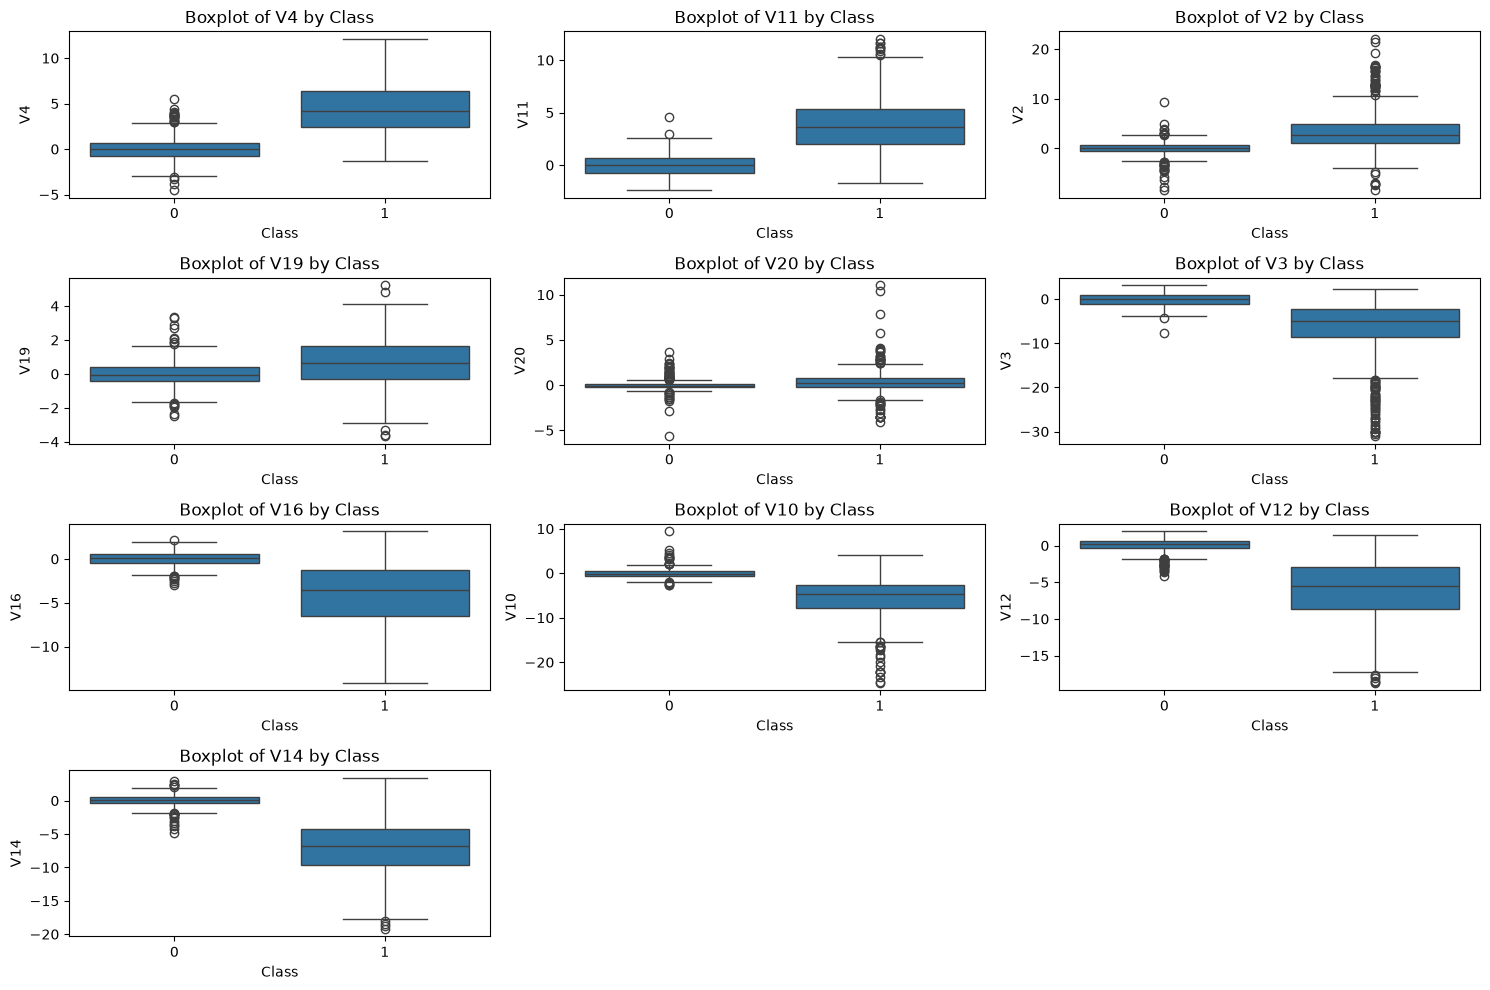

In [26]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features_to_check, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x='Class', y=feature, data=subSample)
    plt.title(f'Boxplot of {feature} by Class')
plt.tight_layout()
plt.show()

In [27]:
def remove_outliers(df,feature):
    lower = df[feature].quantile(0.25)
    upper = df[feature].quantile(0.75)
    IQR = upper - lower
    lower_bound = lower - 1.5*IQR
    upper_bound = upper + 1.5*IQR
    return df[(df[feature]>=lower_bound) & (df[feature]<=upper_bound)]
    
for feature in features_to_check:
    df = remove_outliers(df,feature)

In [28]:
X = df.drop('Class', axis=1)
y = df['Class']

# Initialize scaler
scaler = StandardScaler()

# Fit and transform
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for clarity
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Dimensionality Reduction

Original shape: (196975, 30)
Reduced shape: (196975, 23)


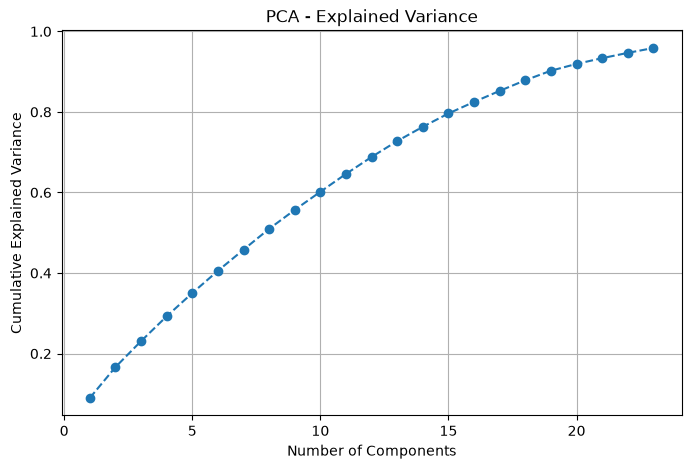

In [29]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
cum_variance = explained_variance.cumsum()

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_variance)+1), cum_variance, marker='o', linestyle='--')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Explained Variance')
plt.grid()
plt.show()

In [30]:
print(f"Number of components chosen: {pca.n_components_}")
pca_columns = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pca_columns)

print(df_pca.head())

Number of components chosen: 23
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  0.753627 -3.346923  0.072023 -0.528806 -0.097861  0.105001 -0.374775   
1 -0.213930 -0.832529 -1.552751 -1.148228  0.895862  0.807324  1.314242   
2  0.864613 -2.223751 -0.086895 -0.791533  1.155909 -1.113616 -0.639167   
3  1.550461 -2.360134  0.258588  0.571681 -0.961300  2.020669  1.549002   
4  1.969652 -1.526596 -1.560185 -0.285247 -0.099900  0.250211  0.529692   

        PC8       PC9      PC10  ...      PC14      PC15      PC16      PC17  \
0  0.651089 -0.501813  0.042800  ... -1.308090 -0.201660  0.644423  0.653375   
1 -1.127388 -0.257063 -0.502268  ...  0.617399 -0.296354 -1.084477  0.775318   
2 -0.844469  1.789936  2.213523  ...  0.260506 -0.463886 -1.444130  0.346940   
3  0.349309  0.475273 -0.057662  ... -0.012271 -0.444990  2.070250 -0.014148   
4 -1.219732 -0.055814 -0.252354  ...  0.593641 -0.183959 -1.004344  0.874908   

       PC18      PC19      PC20     

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, stratify=y, random_state=42
)

print("Train size:", X_train.shape, "Test size:", X_test.shape)

Train size: (157580, 23) Test size: (39395, 23)


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, tree_method = 'hist', device = 'cuda'),
    "SVM": SVC(probability=True, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob) if y_prob is not None else "N/A"
    
    results.append([name, accuracy, precision, recall, f1, roc_auc])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"])
print(results_df)

e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:41:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, f

                 Model  Accuracy  Precision  Recall  F1 Score   ROC AUC
0  Logistic Regression  0.999898        0.0     0.0       0.0  0.936730
1        Decision Tree  0.999797        0.0     0.0       0.0  0.499949
2        Random Forest  0.999898        0.0     0.0       0.0  0.496192
3              XGBoost  0.999898        0.0     0.0       0.0  0.968400
4                  SVM  0.999898        0.0     0.0       0.0  0.804321


e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [33]:
X = df.drop("Class",axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, stratify=y, random_state=42
)

In [34]:
print("Befor SMOTE:")
print(X_train.shape)
print(y_train.shape)
print(y_train.value_counts())

Befor SMOTE:
(157580, 23)
(157580,)
Class
0    157565
1        15
Name: count, dtype: int64


In [35]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [36]:
print("After SMOTE:")
print(X_train_smote.shape)
print(y_train_smote.shape)
print(y_train_smote.value_counts())

After SMOTE:
(315130, 23)
(315130,)
Class
0    157565
1    157565
Name: count, dtype: int64


In [37]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000, solver="liblinear", random_state=42)
lr.fit(X_train_smote, y_train_smote)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `

In [38]:
y_pred = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:, 1]

# Evaluation
print("\nLogistic Regression Results:")
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("Classification Report:\n", classification_report(y_test, y_pred, digits=4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Logistic Regression Results:
ROC AUC: 0.827993704145617
Classification Report:
               precision    recall  f1-score   support

           0     1.0000    0.8627    0.9263     39391
           1     0.0006    0.7500    0.0011         4

    accuracy                         0.8626     39395
   macro avg     0.5003    0.8063    0.4637     39395
weighted avg     0.9999    0.8626    0.9262     39395

Confusion Matrix:
 [[33981  5410]
 [    1     3]]


In [39]:
brf = BalancedRandomForestClassifier(
    n_estimators=200,       # number of trees
    max_depth=None,         # let trees grow fully
    random_state=42,
    n_jobs=-1
)

# Train
brf.fit(X_train_smote, y_train_smote)

,n_estimators,200
,n_jobs,-1
,random_state,42
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0


In [40]:
y_pred = brf.predict(X_test)
y_prob = brf.predict_proba(X_test)[:, 1]

# Evaluation
roc_auc = roc_auc_score(y_test, y_prob)
print("Balanced Random Forest Results:")
print("ROC AUC:", roc_auc)

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Balanced Random Forest Results:
ROC AUC: 0.5848321951714859
Classification Report:
              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999     39391
           1     0.0000    0.0000    0.0000         4

    accuracy                         0.9999     39395
   macro avg     0.4999    0.5000    0.5000     39395
weighted avg     0.9998    0.9999    0.9998     39395

Confusion Matrix:
[[39391     0]
 [    4     0]]


e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

In [41]:
neg, pos = y_train_smote.value_counts()
n_nonfraud = (y_train_smote == 0).sum()
n_fraud = (y_train_smote == 1).sum()
scale_pos_weight = (n_nonfraud) / (n_fraud)
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    scale_pos_weight=scale_pos_weight,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    device='cuda'
)
xgb_model.fit(X_train_smote, y_train_smote)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [42]:
y_pred = xgb_model.predict(X_test)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Results:")
print("ROC AUC:", roc_auc_score(y_test, y_pred_proba))
print("Classification Report:\n", classification_report(y_test, y_pred, digits=4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

XGBoost Results:
ROC AUC: 0.8343212916656089
Classification Report:
               precision    recall  f1-score   support

           0     0.9999    0.9990    0.9995     39391
           1     0.0000    0.0000    0.0000         4

    accuracy                         0.9989     39395
   macro avg     0.4999    0.4995    0.4997     39395
weighted avg     0.9998    0.9989    0.9994     39395

Confusion Matrix:
 [[39353    38]
 [    4     0]]


In [43]:
y_proba = xgb_model.predict_proba(X_test)[:, 1]

# precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# find best threshold (e.g. maximize F1)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-6)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Best Precision:", precisions[best_idx])
print("Best Recall:", recalls[best_idx])
print("Best F1:", f1_scores[best_idx])

# apply best threshold
y_pred_best = (y_proba >= best_threshold).astype(int)

print("\nClassification Report (Best Threshold):")
print(classification_report(y_test, y_pred_best, digits=4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))


Best threshold: 0.0059364303
Best Precision: 0.0009062075215224287
Best Recall: 0.5
Best F1: 0.0018091325257752287

Classification Report (Best Threshold):
              precision    recall  f1-score   support

           0     0.9999    0.9440    0.9712     39391
           1     0.0009    0.5000    0.0018         4

    accuracy                         0.9440     39395
   macro avg     0.5004    0.7220    0.4865     39395
weighted avg     0.9998    0.9440    0.9711     39395

Confusion Matrix:
 [[37186  2205]
 [    2     2]]


In [49]:
svm = LinearSVC(class_weight="balanced", max_iter=10000, random_state=42)
svm_calibrated = CalibratedClassifierCV(svm, cv=5)

In [50]:
svm_calibrated.fit(X_train_smote, y_train_smote)
y_pred = svm_calibrated.predict(X_test)
y_proba = svm_calibrated.predict_proba(X_test)[:,1]

In [51]:
roc_auc = roc_auc_score(y_test, y_proba)
print("SVM Results:")
print(f"ROC AUC: {roc_auc}")
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

SVM Results:
ROC AUC: 0.8400903759742073
Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.8618    0.9258     39391
           1     0.0006    0.7500    0.0011         4

    accuracy                         0.8618     39395
   macro avg     0.5003    0.8059    0.4634     39395
weighted avg     0.9999    0.8618    0.9257     39395

Confusion Matrix:
[[33948  5443]
 [    1     3]]


In [52]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
knn.fit(X_train_smote, y_train_smote)

,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [53]:
y_pred_knn = knn.predict(X_test)
y_pred_proba_knn = knn.predict_proba(X_test)[:, 1]

# Metrics
roc_auc = roc_auc_score(y_test, y_pred_proba_knn)
print("KNN Results:")
print("ROC AUC:", roc_auc)
print("Classification Report:")
print(classification_report(y_test, y_pred_knn, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Results:
ROC AUC: 0.4996192023558681
Classification Report:
              precision    recall  f1-score   support

           0     0.9999    0.9997    0.9998     39391
           1     0.0000    0.0000    0.0000         4

    accuracy                         0.9996     39395
   macro avg     0.4999    0.4998    0.4999     39395
weighted avg     0.9998    0.9996    0.9997     39395

Confusion Matrix:
[[39379    12]
 [    4     0]]


In [71]:
log_reg = LogisticRegression(max_iter=2000, random_state=42)

param_grid = [
    {
    "C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],  # supports l1 and elasticnet
    "class_weight": [None, "balanced"],
    # "l1_ratio": [0, 0.5, 1]  # only used if penalty='elasticnet'
},
{
    "C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "penalty": ["l1", "l2", None],
    "solver": ["saga"], 
    "class_weight": [None, "balanced"]
},
{
    "C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "penalty": ["elasticnet"],
    "solver": ["saga"], 
    "class_weight": [None, "balanced"],
    "l1_ratio": [0, 0.5, 1] 
}
]

# GridSearchCV
grid_search = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    scoring="roc_auc",   # focusing on ROC AUC for imbalance
    cv=5,
    n_jobs=-1,
    verbose=2
)


In [72]:
grid_search.fit(X_train_smote, y_train_smote)

Fitting 5 folds for each of 128 candidates, totalling 640 fits


e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': [0.0001, 0.001, ...], 'class_weight': [None, 'balanced'], 'penalty': ['l1', 'l2'], 'solver': ['liblinear']}, {'C': [0.0001, 0.001, ...], 'class_weight': [None, 'balanced'], 'penalty': ['l1', 'l2', ...], 'solver': ['saga']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this

In [74]:
# Best params & score
print("Best Parameters:", grid_search.best_params_)
print("Best ROC AUC:", grid_search.best_score_)

Best Parameters: {'C': 0.001, 'class_weight': None, 'penalty': 'l2', 'solver': 'liblinear'}
Best ROC AUC: 0.9452627068719319


In [75]:
best_params = {'C': 0.001, 'class_weight': None, 'l1_ratio': 0, 
               'penalty': 'l2', 'solver': 'liblinear'}

# Train final logistic regression with best params
final_model = LogisticRegression(**best_params, max_iter=1000, random_state=42)

In [76]:
final_model.fit(X_train_smote, y_train_smote)

e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.001
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"l1_ratio l1_ratio: float, default=0.0The Elasti

Final Logistic Regression ROC AUC: 0.8350828869538727

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92     39391
           1       0.00      0.75      0.00         4

    accuracy                           0.85     39395
   macro avg       0.50      0.80      0.46     39395
weighted avg       1.00      0.85      0.92     39395


Confusion Matrix:
[[33428  5963]
 [    1     3]]


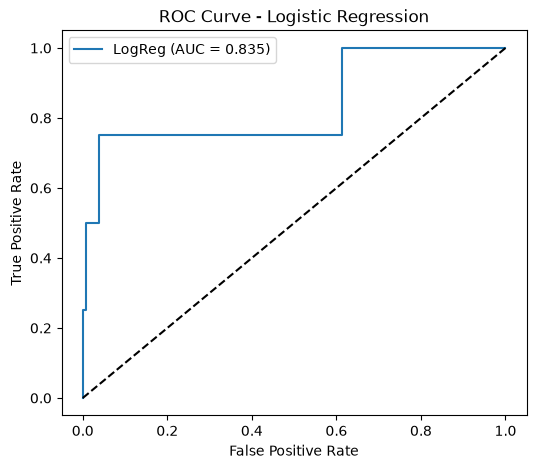

In [77]:
y_pred = final_model.predict(X_test)
y_pred_proba = final_model.predict_proba(X_test)[:,1]

# Evaluation
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("Final Logistic Regression ROC AUC:", roc_auc)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'LogReg (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [78]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_svc = LinearSVC(random_state=42, max_iter=5000)

calibrated = CalibratedClassifierCV(estimator=base_svc, cv=3, method='sigmoid')

param_grid = {
    'estimator__C': [0.0001, 0.001, 0.01, 0.1, 1, 10],
    'estimator__loss': ['squared_hinge', 'hinge']
}

grid_svm = GridSearchCV(
    estimator=calibrated,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2
)


In [79]:
grid_svm.fit(X_train_smote, y_train_smote)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",CalibratedCla...dom_state=42))
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator__C': [0.0001, 0.001, ...], 'estimator__loss': ['squared_hinge', 'hinge']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_m

In [ ]:
print("Best SVM params:", grid_svm.best_params_)
print("Best CV ROC AUC (SVM):", grid_svm.best_score_)
best_svm = grid_svm.best_estimator_ 

Best SVM params: {'estimator__C': 0.0001, 'estimator__loss': 'squared_hinge'}
Best CV ROC AUC (SVM): 0.9445173755061971


In [64]:
sgd = SGDClassifier(loss="hinge", penalty="l2", random_state=42, max_iter=2000)

# Hyperparameter grid (much smaller than SVM)
param_grid = {
    "alpha": [1e-4, 1e-3, 1e-2],   # equivalent to 1/C
    "penalty": ["l2", "elasticnet"],
}

# Stratified CV
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Grid search
grid = GridSearchCV(sgd, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train_smote, y_train_smote)

print("Best Parameters:", grid.best_params_)
print("Best ROC AUC (CV):", grid.best_score_)


Best Parameters: {'alpha': 0.0001, 'penalty': 'elasticnet'}
Best ROC AUC (CV): 0.9322465861745509


In [65]:
best_sgd = grid.best_estimator_
calibrated_sgd = CalibratedClassifierCV(best_sgd, method="sigmoid", cv=3)
calibrated_sgd.fit(X_train_smote, y_train_smote)

# Evaluate on hold-out test set
y_pred = calibrated_sgd.predict(X_test)
y_proba = calibrated_sgd.predict_proba(X_test)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ROC AUC: 0.8133647279835495
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92     39391
           1       0.00      0.75      0.00         4

    accuracy                           0.85     39395
   macro avg       0.50      0.80      0.46     39395
weighted avg       1.00      0.85      0.92     39395

Confusion Matrix:
[[33495  5896]
 [    1     3]]


In [66]:
log_reg_best = LogisticRegression(
    C=1.0, 
    penalty='l2', 
    solver='liblinear',
    class_weight='balanced',
    random_state=42
)
sgd_best = SGDClassifier(
    alpha=0.0001,
    penalty='elasticnet',
    loss='log_loss',  # logistic loss
    class_weight='balanced',
    random_state=42
)
ensemble = VotingClassifier(
    estimators=[('lr', log_reg_best), ('sgd', sgd_best)],
    voting='soft'
)

In [67]:
ensemble.fit(X_train, y_train)

e:\credit-card-fraud-detection\Credit_Card_Fraud_Detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('sgd', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...r='liblinear'), SGDClassifier...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,23


In [68]:
y_pred = ensemble.predict(X_test)
y_pred_proba = ensemble.predict_proba(X_test)[:, 1]

# evaluation
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("ROC AUC:", roc_auc)
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ROC AUC: 0.8233098931227946
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.73      0.84     39391
           1       0.00      0.75      0.00         4

    accuracy                           0.73     39395
   macro avg       0.50      0.74      0.42     39395
weighted avg       1.00      0.73      0.84     39395

Confusion Matrix:
[[28699 10692]
 [    1     3]]


In [69]:
y_proba = ensemble.predict_proba(X_test)[:, 1]

best_threshold = 0.5
best_f1 = 0
best_metrics = None

# Sweep thresholds from 0.001 to 0.5
for thresh in np.linspace(0.001, 0.5, 500):
    y_pred_thresh = (y_proba >= thresh).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_thresh, average='binary', zero_division=0)
    
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = thresh
        best_metrics = (precision, recall, f1)

print(f"Best threshold: {best_threshold:.6f}")
print(f"Precision: {best_metrics[0]:.4f}, Recall: {best_metrics[1]:.4f}, F1: {best_metrics[2]:.4f}")

# Evaluate final confusion matrix at best threshold
y_pred_best = (y_proba >= best_threshold).astype(int)
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))

Best threshold: 0.500000
Precision: 0.0003, Recall: 0.7500, F1: 0.0006
Confusion Matrix:
 [[28699 10692]
 [    1     3]]
